# Project 2: IMDB sentiment with GloVe 50d + a basic tokenizer

This notebook is **self-contained**: it does not import anything from the tutorial repo. Everything the tutorial's `part1` / `part2` packages provided is re-implemented here (embedding loader, vocabulary, tokenizer, encoders, regressor, training loop, cross-validation, plotting, BDA model).

Outline:
1. Config and data
2. Text processing and GloVe loading
3. Evidence that GloVe-50d + this tokenizer suits IMDB (coverage, tokenizer fit, polarity structure, antonym limitation)
4. Task vocabulary and tokenizers
5. Models (embed-and-pool, LSTM, BiLSTM, GRU), training loop, cross validation
6. Experiments, data-size study
7. Error analysis with a Bayesian logistic model (numpyro + arviz)

**Requirements:** `torch numpy pandas scikit-learn nltk matplotlib textstat numpyro arviz` (`pip install numpyro arviz textstat` if missing).

In [49]:
import numpyro
numpyro.set_host_device_count(2)   # must run before JAX is used; lets the 2 MCMC chains run in parallel

import io
import re
import zipfile
from collections import Counter, OrderedDict
from functools import lru_cache
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
import matplotlib.pyplot as plt
import nltk
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import classification_report

NLTK_DIR = Path("./nltk_data").resolve()
NLTK_DIR.mkdir(exist_ok=True)
NLTK_DIR.chmod(0o700)                  # private to you, so NLTK accepts it
nltk.data.path.insert(0, str(NLTK_DIR))
for pkg in ['opinion_lexicon', 'stopwords', 'punkt', 'punkt_tab', 'cmudict']:
    nltk.download(pkg, download_dir=str(NLTK_DIR))

[nltk_data] Downloading package opinion_lexicon to
[nltk_data]     /home/beau/.local/share/Trash/files/project2/nltk_data
[nltk_data]     ...
[nltk_data]   Package opinion_lexicon is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/beau/.local/share/Trash/files/project2/nltk_data
[nltk_data]     ...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     /home/beau/.local/share/Trash/files/project2/nltk_data
[nltk_data]     ...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/beau/.local/share/Trash/files/project2/nltk_data
[nltk_data]     ...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/beau/.local/share/Trash/files/project2/nltk_data
[nltk_data]     ...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package cmudict t

## 0. Config

`FAST_DEV = True` gives a quick smoke test (small subsets, few epochs). Set it to `False` for real runs.

In [50]:
FAST_DEV = False  # set to True for quick development runs (fewer epochs, fewer folds, smaller dataset)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", DEVICE)

SEEDS = [0] if FAST_DEV else [0, 3, 5]
NUM_FOLDS = 3 if FAST_DEV else 5
NUM_EPOCHS = 3 if FAST_DEV else 20
TRAIN_SUBSET = 4000 if FAST_DEV else None    # None = full 25k reviews
TEST_SUBSET = 5000 if FAST_DEV else None     # None = full 25k reviews
MAX_LEN_RNN = 256                             # truncation length for recurrent models
DEVTEST_SIZE = 1000
GLOVE_MAX_WORDS = None                        # e.g. 400_000 to load only the most frequent words (the file is sorted by frequency)

results_folder = Path("./results_imdb")
results_folder.mkdir(parents=True, exist_ok=True)

torch.manual_seed(0)
np.random.seed(0)

Device: cuda


## 1. Data

In [51]:
splits = {'train': 'data/train-00000-of-00001.parquet', 'test': 'data/test-00000-of-00001.parquet'}
df_train = pd.read_parquet("hf://datasets/mteb/imdb/" + splits["train"])
df_test = pd.read_parquet("hf://datasets/mteb/imdb/" + splits["test"])
print(df_train.shape, df_test.shape, df_train.columns.tolist())
print(df_train['label'].value_counts())

(24904, 3) (24678, 3) ['text', 'label', 'label_text']
label
1    12472
0    12432
Name: count, dtype: int64


In [52]:
CLASS_NAMES = ['negative', 'positive']
NUM_CLASSES = len(CLASS_NAMES)

rs = np.random.RandomState(0)

train_texts = df_train['text'].tolist()
train_labels = df_train['label'].astype(int).tolist()
if TRAIN_SUBSET is not None:
    idx = rs.permutation(len(train_texts))[:TRAIN_SUBSET]
    train_texts = [train_texts[i] for i in idx]
    train_labels = [train_labels[i] for i in idx]

test_texts = df_test['text'].tolist()
test_labels = df_test['label'].astype(int).tolist()
if TEST_SUBSET is not None:
    idx = rs.permutation(len(test_texts))[:TEST_SUBSET]
    test_texts = [test_texts[i] for i in idx]
    test_labels = [test_labels[i] for i in idx]

print(len(train_texts), "train reviews;", len(test_texts), "test reviews")

24904 train reviews; 24678 test reviews


In [53]:
word_counts = np.array([len(t.split()) for t in train_texts])
print(f"words/review: mean={word_counts.mean():.0f} median={np.median(word_counts):.0f} "
      f"p95={np.percentile(word_counts, 95):.0f} max={word_counts.max()}")
print("Reviews containing <br />:", np.mean(['<br />' in t for t in train_texts]).round(3))
print(train_texts[0][:400])

words/review: mean=234 median=174 p95=599 max=2470
Reviews containing <br />: 0.587
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student name


## 2. Text processing and GloVe

### 2.1 Cleaning and base tokenization

We strip HTML, lowercase, and tokenize with NLTK's `word_tokenize` (sentence splitting + Treebank-style rules: `wasn't` -> `was`, `n't`). Tokenization is the slowest step, so results are cached per text; every tokenizer variant below filters/truncates these cached base tokens.

In [54]:
HTML_RE = re.compile(r"<[^>]+>")
WS_RE = re.compile(r"\s+")

def clean_text(text: str) -> str:
    """Strip HTML tags (IMDB has lots of <br />) and normalise whitespace."""
    return WS_RE.sub(" ", HTML_RE.sub(" ", text)).strip()

@lru_cache(maxsize=None)
def base_tokens(text: str) -> tuple:
    """Lowercased NLTK tokens of the cleaned text (cached)."""
    return tuple(nltk.word_tokenize(clean_text(text).lower()))

def is_punct(tok: str) -> bool:
    return not any(c.isalnum() for c in tok)

print(base_tokens("This movie wasn't good at all!<br /><br />Great premise, but terrible execution... 3/10."))

('this', 'movie', 'was', "n't", 'good', 'at', 'all', '!', 'great', 'premise', ',', 'but', 'terrible', 'execution', '...', '3/10', '.')


### 2.2 Vocabulary and GloVe loader

In [55]:
class Vocabulary:
    """Bidirectional word <-> 0-based id mapping with a default (unknown) word."""
    def __init__(self, words, default='<unk>'):
        self.id2word = list(words)
        self.word2id = {w: i for i, w in enumerate(self.id2word)}
        self.default_word = default
        self.default_index = self.word2id[default]

    def index(self, word):
        return self.word2id.get(word, self.default_index)

    def __contains__(self, word):
        return word in self.word2id

    def __len__(self):
        return len(self.id2word)

    def items(self):
        return enumerate(self.id2word)


class PretrainedEmbeddings:
    """Loads word vectors (word v1 ... vD per line) from a zipped text file without unzipping it."""
    def __init__(self, path, dims, max_words=None):
        words, chunks, buf, seen = [], [], [], set()
        with zipfile.ZipFile(path) as zf:
            name = [n for n in zf.namelist() if not n.endswith('/') and not n.startswith('__MACOSX')][0]
            with zf.open(name) as f:
                for i, line in enumerate(io.TextIOWrapper(f, encoding='utf8', errors='ignore')):
                    if max_words is not None and len(words) >= max_words:
                        break
                    parts = line.rstrip().rsplit(' ', dims)   # robust to odd tokens; also skips a header line
                    if len(parts) != dims + 1 or parts[0] in seen:
                        continue
                    seen.add(parts[0])
                    words.append(parts[0])
                    buf.append(np.asarray(parts[1:], dtype=np.float32))
                    if len(buf) == 100_000:
                        chunks.append(np.stack(buf)); buf = []
        if buf:
            chunks.append(np.stack(buf))
        self.words = words
        self.vectors = np.concatenate(chunks, 0)
        self.w2i = {w: i for i, w in enumerate(words)}
        self.dims = dims

    def __contains__(self, word):
        return word in self.w2i

    def __len__(self):
        return len(self.words)

    def embed_word(self, word):
        return self.vectors[self.w2i[word]]

In [56]:
GLOVE_ZIP = "glove.2024.wikigiga.50d.zip"
GLOVE_URL = 'https://surfdrive.surf.nl/s/qYfZ6PiNrMLCwpS/download'
if not Path(GLOVE_ZIP).is_file():
    urlretrieve(GLOVE_URL, GLOVE_ZIP)     # keep it zipped, the loader reads the zip directly
print(f"{Path(GLOVE_ZIP).stat().st_size / 1e6:.0f} MB")

301 MB


In [57]:
%%time
glove = PretrainedEmbeddings(GLOVE_ZIP, 50, max_words=GLOVE_MAX_WORDS)
print("GloVe matrix:", glove.vectors.shape)
print("First words:", glove.words[:15])

GloVe matrix: (1291147, 50)
First words: ['the', ',', '.', 'of', 'to', 'and', 'in', 'a', '"', '-', "'s", 'for', 'that', 'on', 'was']
CPU times: user 17.5 s, sys: 732 ms, total: 18.2 s
Wall time: 18.2 s


## 3. Is GloVe-50d + this tokenizer a good fit for IMDB?

### 3.1 Vocabulary coverage (against the *full* GloVe vocabulary)

In [58]:
%%time
token_counts = Counter()
for t in train_texts:
    token_counts.update(base_tokens(t))

n_total = sum(token_counts.values())
covered = {w for w in token_counts if w in glove}
print(f"Token types: {len(token_counts):,} | covered by GloVe: {len(covered) / len(token_counts):.1%}")
print(f"Token occurrences: {n_total:,} | covered: {sum(token_counts[w] for w in covered) / n_total:.2%}")

oov = Counter({w: c for w, c in token_counts.items() if w not in glove})
print("\nMost frequent OOV tokens:")
print([(w, c) for w, c in oov.most_common(40)])

Token types: 100,837 | covered by GloVe: 67.6%
Token occurrences: 6,679,994 | covered: 99.09%

Most frequent OOV tokens:
[('..', 1618), ('\x96', 1337), ('sci-fi', 539), ('low-budget', 270), ('film-making', 260), ('2.', 221), ('make-up', 196), ('b-movie', 182), ('10.', 180), ('and/or', 177), ('so-called', 163), ('3.', 153), ('one-liners', 141), ('writer/director', 139), ('must-see', 126), ('real-life', 125), ('rip-off', 120), ('ok.', 117), ('camera-work', 110), ('all-time', 110), ('4.', 108), ('hit-man', 97), ('on-screen', 95), ('one-dimensional', 94), ('close-ups', 93), ('made-for-tv', 91), ('voice-over', 90), ('well-known', 85), ('film-makers', 81), ('would-be', 80), ('middle-aged', 79), ('no-one', 76), ('year-old', 74), ('5.', 73), ('pg-13', 72), ('thought-provoking', 72), ('well-written', 71), ('set-up', 70), ('dont', 70), ('top-notch', 69)]
CPU times: user 44.2 s, sys: 54.8 s, total: 1min 39s
Wall time: 1min 38s


### 3.2 Tokenizer fit: contractions, punctuation, hyphens

In [59]:
for w in ["n't", "'s", "'re", "'ve", "'ll", "'m", "-", "--", "...", "!", "?", "/", "10"]:
    print(f"{w!r:8} in GloVe: {w in glove}")

print()
for s in ["It wasn't a great film, but I couldn't stop watching.",
          "A well-known actor's best role -- 8/10!",
          "Can't wait; it's a must-see."]:
    toks = base_tokens(s)
    print(list(toks), "-> OOV:", [t for t in toks if t not in glove])

"n't"    in GloVe: True
"'s"     in GloVe: True
"'re"    in GloVe: True
"'ve"    in GloVe: True
"'ll"    in GloVe: True
"'m"     in GloVe: True
'-'      in GloVe: True
'--'     in GloVe: True
'...'    in GloVe: True
'!'      in GloVe: True
'?'      in GloVe: True
'/'      in GloVe: True
'10'     in GloVe: True

['it', 'was', "n't", 'a', 'great', 'film', ',', 'but', 'i', 'could', "n't", 'stop', 'watching', '.'] -> OOV: []
['a', 'well-known', 'actor', "'s", 'best', 'role', '--', '8/10', '!'] -> OOV: ['well-known']
['ca', "n't", 'wait', ';', 'it', "'s", 'a', 'must-see', '.'] -> OOV: ['must-see']


### 3.3 Cosine similarity and nearest neighbours

Neighbour search is restricted to the 200k most frequent words (the file is frequency-sorted), which avoids rare junk tokens in the results.

In [60]:
NN_LIMIT = min(200_000, len(glove))
E_nn = glove.vectors[:NN_LIMIT]
E_nn_norm = E_nn / (np.linalg.norm(E_nn, axis=1, keepdims=True) + 1e-9)

def vec(w):
    return glove.embed_word(w)

def cos(u, v):
    return float(np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v) + 1e-9))

def topk_words(v, k=10, exclude=()):
    sims = E_nn_norm @ (v / (np.linalg.norm(v) + 1e-9))
    out = []
    for i in np.argsort(-sims)[: k + len(exclude) + 1]:
        w = glove.words[int(i)]
        if w not in exclude:
            out.append((w, round(float(sims[i]), 3)))
        if len(out) == k:
            break
    return out

### 3.4 Polarity structure (NLTK opinion lexicon)

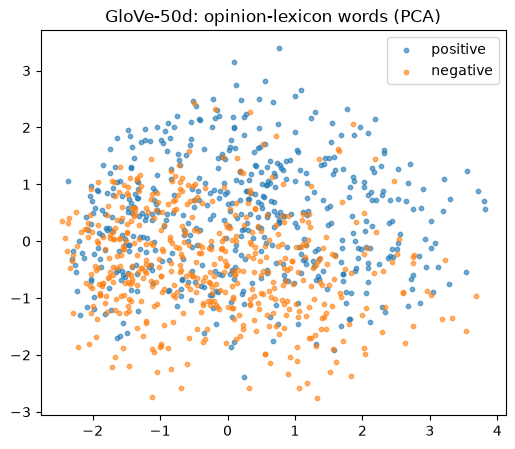

Linear probe, polarity accuracy (5-fold): 0.843 (chance 0.5)


In [61]:
from nltk.corpus import opinion_lexicon
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

pos_lex = set(opinion_lexicon.positive())
neg_lex = set(opinion_lexicon.negative())

lex_rs = np.random.RandomState(0)
pos_words = [w for w in sorted(pos_lex) if w in glove]
neg_words = [w for w in sorted(neg_lex) if w in glove]
pos_words = list(lex_rs.choice(pos_words, min(500, len(pos_words)), replace=False))
neg_words = list(lex_rs.choice(neg_words, min(500, len(neg_words)), replace=False))

X_lex = np.stack([vec(w) for w in pos_words + neg_words])
y_lex = np.array([1] * len(pos_words) + [0] * len(neg_words))

Z = PCA(n_components=2, random_state=0).fit_transform(X_lex)
plt.figure(figsize=(6, 5))
plt.scatter(Z[y_lex == 1, 0], Z[y_lex == 1, 1], s=10, alpha=.6, label='positive')
plt.scatter(Z[y_lex == 0, 0], Z[y_lex == 0, 1], s=10, alpha=.6, label='negative')
plt.legend(); plt.title("GloVe-50d: opinion-lexicon words (PCA)"); plt.show()

# PCA can hide structure; a linear probe tells us whether polarity is linearly decodable
acc = cross_val_score(LogisticRegression(max_iter=2000), X_lex, y_lex, cv=5).mean()
print(f"Linear probe, polarity accuracy (5-fold): {acc:.3f} (chance 0.5)")

### 3.5 Known limitation: antonyms live close together

In [62]:
for a, b in [('good', 'bad'), ('great', 'terrible'), ('love', 'hate'), ('boring', 'exciting'), ('good', 'great'), ('bad', 'awful')]:
    print(f"cos({a}, {b}) = {cos(vec(a), vec(b)):.3f}")
print()
for w in ['good', 'terrible', 'boring', 'amazing', 'waste']:
    print(w, '->', topk_words(vec(w), 10, exclude={w}))

cos(good, bad) = 0.814
cos(great, terrible) = 0.621
cos(love, hate) = 0.630
cos(boring, exciting) = 0.694
cos(good, great) = 0.842
cos(bad, awful) = 0.804

good -> [('better', 0.939), ('really', 0.938), ('always', 0.928), ('something', 0.921), ('kind', 0.92), ('little', 0.919), ('make', 0.919), ('way', 0.917), ('think', 0.916), ('enough', 0.908)]
terrible -> [('horrible', 0.932), ('awful', 0.887), ('dreadful', 0.856), ('tragedy', 0.841), ('horrific', 0.826), ('tragic', 0.82), ('horrendous', 0.817), ('unfortunately', 0.811), ('worse', 0.811), ('mistake', 0.81)]
boring -> [('funny', 0.836), ('awfully', 0.823), ('pretty', 0.809), ('weird', 0.805), ('silly', 0.797), ('bored', 0.79), ('stupid', 0.78), ('incredibly', 0.774), ('stuff', 0.77), ('lazy', 0.77)]
amazing -> [('incredible', 0.942), ('fantastic', 0.898), ('wonderful', 0.873), ('marvelous', 0.873), ('awesome', 0.867), ('terrific', 0.854), ('exciting', 0.841), ('astonishing', 0.841), ('remarkable', 0.832), ('unbelievable', 0.822)]
was

## 4. Task vocabulary and tokenizers

**Task vocabulary.** The full GloVe table has ~1.2M rows, which is wasteful to carry through every model (and to save for every fold). We keep only the GloVe vectors for words that occur in the IMDB texts (train + test texts; no labels are used, so this is only a vocabulary choice and words never seen in training still keep their pretrained GloVe vector). Tokens that GloVe does not know map to `<unk>`.

Special rows: `<pad>` = zeros, `<unk>` = mean GloVe vector.

In [63]:
%%time
all_counts = Counter(token_counts)
for t in test_texts:
    all_counts.update(base_tokens(t))

task_words = ['<pad>', '<unk>'] + sorted(w for w in all_counts if w in glove)
task_vocab = Vocabulary(task_words, default='<unk>')
PAD_ID, UNK_ID = task_vocab.index('<pad>'), task_vocab.default_index

TASK_MATRIX = np.zeros((len(task_vocab), glove.dims), dtype=np.float32)
TASK_MATRIX[UNK_ID] = glove.vectors.mean(0)
for i, w in task_vocab.items():
    if i > UNK_ID:
        TASK_MATRIX[i] = glove.vectors[glove.w2i[w]]
TASK_MATRIX = torch.tensor(TASK_MATRIX)
print("Task vocab:", len(task_vocab), "| matrix:", tuple(TASK_MATRIX.shape), "| PAD, UNK:", PAD_ID, UNK_ID)

Task vocab: 88683 | matrix: (88683, 50) | PAD, UNK: 0 1
CPU times: user 43 s, sys: 53 s, total: 1min 36s
Wall time: 1min 35s


**Tokenizers.** One class, configured two ways:
- *BoW-style* (embed-and-pool): no punctuation, stopwords removed with a custom list that **keeps negators** (NLTK's list contains `not`, `no`, `nor`, `don`, `couldn`, ...).
- *RNN-style*: keep everything, but truncate to `MAX_LEN_RNN` tokens (`head`, or `headtail` which keeps the first and last N/2 since reviews often give the verdict at the end).

In [64]:
from nltk.corpus import stopwords

NEGATORS = {
    "not", "no", "nor", "never", "n't", "nt", "cannot", "neither", "none", "nothing", "nobody", "nowhere",
    "don", "doesn", "didn", "isn", "aren", "wasn", "weren", "won", "wouldn", "shouldn", "couldn",
    "hasn", "haven", "hadn", "mustn", "needn", "shan", "ain", "mightn",
    "but", "very", "too", "only", "against",     # contrast / intensity words that matter for sentiment
}
STOPWORDS_KEEP_NEG = set(stopwords.words('english')) - NEGATORS
print(len(set(stopwords.words('english'))), "->", len(STOPWORDS_KEEP_NEG), "stopwords after protecting negators")


class ReviewTokenizer:
    """Maps a review to tokens / vocabulary ids. Built on the cached base tokens."""
    def __init__(self, vocab, remove_punct=False, drop_words=None, max_len=None, truncation='head'):
        assert truncation in ('head', 'headtail')
        self.vocab = vocab
        self.remove_punct = remove_punct
        self.drop_words = drop_words or set()
        self.max_len = max_len
        self.truncation = truncation

    def tokens(self, text):
        toks = base_tokens(text)
        if self.remove_punct:
            toks = [t for t in toks if not is_punct(t)]
        if self.drop_words:
            toks = [t for t in toks if t not in self.drop_words]
        toks = list(toks)
        if self.max_len is not None and len(toks) > self.max_len:
            if self.truncation == 'head':
                toks = toks[:self.max_len]
            else:
                half = self.max_len // 2
                toks = toks[:half] + toks[-half:]
        return toks

    def ids(self, text):
        ids = [self.vocab.index(t) for t in self.tokens(text)]
        return ids if ids else [self.vocab.default_index]    # never return an empty sequence


tok_bow = ReviewTokenizer(task_vocab, remove_punct=True, drop_words=STOPWORDS_KEEP_NEG)
tok_bow_all = ReviewTokenizer(task_vocab, remove_punct=True)                      # ablation: keep every stopword
tok_rnn = ReviewTokenizer(task_vocab, max_len=MAX_LEN_RNN, truncation='head')
tok_rnn_ht = ReviewTokenizer(task_vocab, max_len=MAX_LEN_RNN, truncation='headtail')
tok_full = ReviewTokenizer(task_vocab)                                            # no filtering, no truncation (for features)

demo = "This movie wasn't good at all!<br /><br />Great premise, but terrible execution... 3/10."
for name, t in [('bow', tok_bow), ('bow (keep stopwords)', tok_bow_all), ('rnn', tok_rnn)]:
    print(f"{name:22}", t.tokens(demo))

198 -> 171 stopwords after protecting negators
bow                    ['movie', "n't", 'good', 'great', 'premise', 'but', 'terrible', 'execution', '3/10']
bow (keep stopwords)   ['this', 'movie', 'was', "n't", 'good', 'at', 'all', 'great', 'premise', 'but', 'terrible', 'execution', '3/10']
rnn                    ['this', 'movie', 'was', "n't", 'good', 'at', 'all', '!', 'great', 'premise', ',', 'but', 'terrible', 'execution', '...', '3/10', '.']


## 5. Models

### 5.1 Encoders

Both encoders take a padded batch of ids with shape `(batch, max_len)` and return `(batch, enc_dim)`.
- `EmbedAndPoolEncoder`: embeds, then mean (or sum) pools over the *non-pad* positions only.
- `RNNEncoder`: LSTM or GRU, optionally bidirectional, with word dropout (training only: random tokens are replaced by `<unk>`). It uses packed sequences so padding never affects the state, and returns the final state (forward and backward final states concatenated if bidirectional).

In [65]:
class EmbedAndPoolEncoder(nn.Module):
    def __init__(self, embedding_matrix, average_pool=True, padding_idx=0, freeze_embeddings=True):
        super().__init__()
        self.average_pool = average_pool
        self.pad_idx = padding_idx
        self.embedding = nn.Embedding.from_pretrained(embedding_matrix, freeze=freeze_embeddings, padding_idx=padding_idx)

    @property
    def enc_dim(self):
        return self.embedding.embedding_dim

    def forward(self, x):
        mask = x.ne(self.pad_idx)                                   # (B, L)
        e = self.embedding(x) * mask.unsqueeze(-1)                  # (B, L, D), pads zeroed
        h = e.sum(1)
        if self.average_pool:
            h = h / mask.sum(1, keepdim=True).clamp(min=1)
        return h


class RNNEncoder(nn.Module):
    def __init__(self, hidden_size, embedding_matrix, rnn_type='lstm', bidirectional=False, num_layers=1,
                 padding_idx=0, unk_idx=1, freeze_embeddings=True, word_dropout=0.0, dropout=0.0):
        super().__init__()
        assert rnn_type in ('lstm', 'gru')
        self.rnn_type, self.bidirectional = rnn_type, bidirectional
        self.hidden_size, self.pad_idx, self.unk_idx = hidden_size, padding_idx, unk_idx
        self.word_dropout = word_dropout
        self.embedding = nn.Embedding.from_pretrained(embedding_matrix, freeze=freeze_embeddings, padding_idx=padding_idx)
        cls = nn.LSTM if rnn_type == 'lstm' else nn.GRU
        self.rnn = cls(embedding_matrix.shape[1], hidden_size, num_layers=num_layers, batch_first=True,
                       bidirectional=bidirectional, dropout=dropout if num_layers > 1 else 0.0)

    @property
    def enc_dim(self):
        return self.hidden_size * (2 if self.bidirectional else 1)

    def forward(self, x):
        if self.training and self.word_dropout > 0:
            drop = (torch.rand(x.shape, device=x.device) < self.word_dropout) & x.ne(self.pad_idx)
            x = x.masked_fill(drop, self.unk_idx)
        lengths = x.ne(self.pad_idx).sum(1).clamp(min=1).cpu()
        packed = pack_padded_sequence(self.embedding(x), lengths, batch_first=True, enforce_sorted=False)
        _, h = self.rnn(packed)
        if self.rnn_type == 'lstm':
            h = h[0]                                                # (layers * dirs, B, H)
        return torch.cat([h[-2], h[-1]], -1) if self.bidirectional else h[-1]

### 5.2 Softmax regressor

MLP on top of the encoding, with `LogSoftmax` output (so the model predicts log-probabilities).

In [66]:
class SoftmaxRegressor(nn.Module):
    def __init__(self, encoder, hidden_size1, hidden_size2, num_classes, dropout=0.1):
        super().__init__()
        self.encoder = encoder
        self.net = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(encoder.enc_dim, hidden_size1), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden_size1, hidden_size2), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden_size2, num_classes),
            nn.LogSoftmax(dim=-1),
        )

    def forward(self, x):
        return self.net(self.encoder(x))


def build_model(cfg):
    """cfg: dict with enc_type in {'embed-and-pool','lstm','bilstm','gru'}, enc_kwargs, regressor_kwargs."""
    matrix = TASK_MATRIX.clone()          # clone: with trainable embeddings we must not modify the shared matrix
    et, kw = cfg['enc_type'], dict(cfg['enc_kwargs'])
    if et == 'embed-and-pool':
        enc = EmbedAndPoolEncoder(matrix, padding_idx=PAD_ID, **kw)
    elif et in ('lstm', 'bilstm', 'gru'):
        enc = RNNEncoder(embedding_matrix=matrix, rnn_type='gru' if et == 'gru' else 'lstm',
                         bidirectional=(et == 'bilstm'), padding_idx=PAD_ID, unk_idx=UNK_ID, **kw)
    else:
        raise ValueError(et)
    return SoftmaxRegressor(enc, num_classes=NUM_CLASSES, **cfg['regressor_kwargs'])

### 5.3 Training, prediction, saving and loading

In [67]:
def collate(id_lists):
    return pad_sequence([torch.tensor(s, dtype=torch.long) for s in id_lists], batch_first=True, padding_value=PAD_ID)


@torch.no_grad()
def predict_ids(model, id_lists, batch_size=64, device='cpu'):
    """Log-probs for tokenized inputs. Sorts by length for speed, returns in the original order."""
    model.eval().to(device)
    order = np.argsort([len(s) for s in id_lists])
    out = np.zeros((len(id_lists), NUM_CLASSES), dtype=np.float32)
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        out[idx] = model(collate([id_lists[i] for i in idx]).to(device)).cpu().numpy()
    return out


def predict_logprobs(model, tokenizer, texts, batch_size=64, device='cpu'):
    return predict_ids(model, [tokenizer.ids(t) for t in texts], batch_size, device)


def evaluate(model, id_lists, labels, batch_size=64, device='cpu'):
    lp = predict_ids(model, id_lists, batch_size, device)
    y = np.asarray(labels)
    return float(-lp[np.arange(len(y)), y].mean()), float((lp.argmax(-1) == y).mean())


def train(train_pairs, val_pairs, tokenizer, cfg, opt_kwargs, device, save_to, seed=0, verbose=True):
    """
    Trains one model, keeps the epoch with the lowest validation loss, saves it to save_to/model.pt.
    Returns (metrics per epoch, best epoch index).
    """
    o = {'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 64, 'num_epochs': NUM_EPOCHS}
    o.update(opt_kwargs or {})
    torch.manual_seed(seed)
    rng = np.random.RandomState(seed)

    tr_ids, tr_y = [tokenizer.ids(t) for t, _ in train_pairs], np.array([l for _, l in train_pairs])
    va_ids, va_y = [tokenizer.ids(t) for t, _ in val_pairs], np.array([l for _, l in val_pairs])

    model = build_model(cfg).to(device)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad],
                           lr=o['learning_rate'], weight_decay=o['weight_decay'])
    loss_fn = nn.NLLLoss()

    metrics, best_epoch, best_state, best_val = [], 0, None, float('inf')
    for epoch in range(o['num_epochs']):
        model.train()
        perm = rng.permutation(len(tr_ids))
        total, correct = 0.0, 0
        for start in range(0, len(perm), o['batch_size']):
            idx = perm[start:start + o['batch_size']]
            xb = collate([tr_ids[i] for i in idx]).to(device)
            yb = torch.tensor(tr_y[idx], dtype=torch.long, device=device)
            opt.zero_grad()
            lp = model(xb)
            loss = loss_fn(lp, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            total += loss.item() * len(idx)
            correct += (lp.argmax(-1) == yb).sum().item()
        val_loss, val_acc = evaluate(model, va_ids, va_y, device=device)
        metrics.append({'epoch': epoch, 'train_loss': total / len(perm), 'train_acc': correct / len(perm),
                        'val_loss': val_loss, 'val_acc': val_acc})
        if verbose:
            m = metrics[-1]
            print(f"epoch {epoch:2d} | train loss {m['train_loss']:.4f} acc {m['train_acc']:.4f} | "
                  f"val loss {m['val_loss']:.4f} acc {m['val_acc']:.4f}")
        if val_loss < best_val:
            best_val, best_epoch = val_loss, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    # frozen embeddings are identical to TASK_MATRIX, so we do not store them (saves a lot of disk)
    if cfg['enc_kwargs'].get('freeze_embeddings', True):
        best_state = {k: v for k, v in best_state.items() if 'embedding.weight' not in k}
    Path(save_to).mkdir(parents=True, exist_ok=True)
    torch.save({'cfg': cfg, 'state': best_state, 'best_epoch': best_epoch}, Path(save_to) / "model.pt")
    return metrics, best_epoch


def load_model(save_to):
    ckpt = torch.load(Path(save_to) / "model.pt", map_location='cpu')
    model = build_model(ckpt['cfg'])
    missing, unexpected = model.load_state_dict(ckpt['state'], strict=False)
    assert not unexpected and all('embedding.weight' in k for k in missing), (missing, unexpected)
    return model.eval()

### 5.4 Data splits

Stratified k-fold on the training set (our cross-validation), and a stratified split of the test set into `devtest` (for analysis) and `test` (unseen).

In [68]:
def cross_validation_split(pairs, k, seed):
    labels = [l for _, l in pairs]
    folds = []
    for tr, va in StratifiedKFold(n_splits=k, shuffle=True, random_state=seed).split(np.zeros(len(labels)), labels):
        folds.append({'training': [pairs[i] for i in tr], 'validation': [pairs[i] for i in va]})
    return folds


def split_test_devtest(texts, labels, devtest_size, seed):
    dev_idx, test_idx = train_test_split(np.arange(len(texts)), train_size=devtest_size, stratify=labels, random_state=seed)
    return {
        'devtest': [(texts[i], labels[i]) for i in dev_idx], 'devtest_ids': [int(i) for i in dev_idx],
        'test': [(texts[i], labels[i]) for i in test_idx], 'test_ids': [int(i) for i in test_idx],
    }


train_pairs = list(zip(train_texts, train_labels))
my_cross_validation_sets = [cross_validation_split(train_pairs, NUM_FOLDS, s) for s in SEEDS]
my_test_sets = [split_test_devtest(test_texts, test_labels, DEVTEST_SIZE, s) for s in SEEDS]
print(len(my_cross_validation_sets[0][0]['training']), "train /", len(my_cross_validation_sets[0][0]['validation']), "val per fold")
print(len(my_test_sets[0]['devtest']), "devtest /", len(my_test_sets[0]['test']), "test")

19923 train / 4981 val per fold
1000 devtest / 23678 test


## 6. Experiments

### 6.1 Sanity check: one training run per encoder

Watch `val loss`: if it rises while `train loss` keeps falling, the model is overfitting (more dropout / word dropout / weight decay, smaller hidden size).

In [69]:
cfg_pool = {'enc_type': 'embed-and-pool', 'enc_kwargs': {'freeze_embeddings': True},
            'regressor_kwargs': {'hidden_size1': 50, 'hidden_size2': 50, 'dropout': 0.5}}
fold0 = my_cross_validation_sets[0][0]
metrics, best_epoch = train(fold0['training'], fold0['validation'], tok_bow, cfg_pool,
                            {}, DEVICE, results_folder / "tmp-pool")
print("best epoch:", best_epoch, "| val acc:", metrics[best_epoch]['val_acc'])

epoch  0 | train loss 0.6659 acc 0.5895 | val loss 0.5964 acc 0.7007
epoch  1 | train loss 0.6225 acc 0.6573 | val loss 0.5779 acc 0.7105
epoch  2 | train loss 0.6189 acc 0.6624 | val loss 0.5792 acc 0.7167
epoch  3 | train loss 0.6163 acc 0.6657 | val loss 0.5724 acc 0.7197
epoch  4 | train loss 0.6150 acc 0.6716 | val loss 0.5651 acc 0.7272
epoch  5 | train loss 0.6104 acc 0.6704 | val loss 0.5728 acc 0.7278
epoch  6 | train loss 0.6107 acc 0.6662 | val loss 0.5791 acc 0.7278
epoch  7 | train loss 0.6120 acc 0.6685 | val loss 0.5646 acc 0.7250
epoch  8 | train loss 0.6100 acc 0.6689 | val loss 0.5624 acc 0.7276
epoch  9 | train loss 0.6052 acc 0.6745 | val loss 0.5694 acc 0.7233
epoch 10 | train loss 0.6069 acc 0.6735 | val loss 0.5782 acc 0.7235
epoch 11 | train loss 0.6063 acc 0.6769 | val loss 0.5777 acc 0.7089
epoch 12 | train loss 0.6061 acc 0.6741 | val loss 0.5658 acc 0.7266
epoch 13 | train loss 0.6099 acc 0.6756 | val loss 0.5637 acc 0.7294
epoch 14 | train loss 0.6071 acc 0

In [70]:
cfg_lstm = {'enc_type': 'lstm', 'enc_kwargs': {'freeze_embeddings': True, 'hidden_size': 64, 'word_dropout': 0.1},
            'regressor_kwargs': {'hidden_size1': 50, 'hidden_size2': 50, 'dropout': 0.1}}
metrics, best_epoch = train(fold0['training'], fold0['validation'], tok_rnn, cfg_lstm,
                            {'batch_size': 32}, DEVICE, results_folder / "tmp-lstm")
print("best epoch:", best_epoch, "| val acc:", metrics[best_epoch]['val_acc'])

epoch  0 | train loss 0.6598 acc 0.6030 | val loss 0.6134 acc 0.6551
epoch  1 | train loss 0.5883 acc 0.7050 | val loss 0.5572 acc 0.7362
epoch  2 | train loss 0.5238 acc 0.7587 | val loss 0.4662 acc 0.7868
epoch  3 | train loss 0.4581 acc 0.7935 | val loss 0.4121 acc 0.8143
epoch  4 | train loss 0.4179 acc 0.8160 | val loss 0.4275 acc 0.8253
epoch  5 | train loss 0.3993 acc 0.8240 | val loss 0.3731 acc 0.8366
epoch  6 | train loss 0.3889 acc 0.8327 | val loss 0.3603 acc 0.8396
epoch  7 | train loss 0.3762 acc 0.8385 | val loss 0.3653 acc 0.8440
epoch  8 | train loss 0.3664 acc 0.8407 | val loss 0.3526 acc 0.8498
epoch  9 | train loss 0.3594 acc 0.8457 | val loss 0.3735 acc 0.8290
epoch 10 | train loss 0.3467 acc 0.8536 | val loss 0.3518 acc 0.8498
epoch 11 | train loss 0.3430 acc 0.8546 | val loss 0.3396 acc 0.8524
epoch 12 | train loss 0.3362 acc 0.8584 | val loss 0.3386 acc 0.8550
epoch 13 | train loss 0.3255 acc 0.8650 | val loss 0.3621 acc 0.8514
epoch 14 | train loss 0.3224 acc 0

### 6.2 Cross validation

`run_cv` runs every seed x fold for one configuration and records the best-epoch validation metrics. The tokenizer and config of each system are stored by name; the analysis section reuses them.

In [71]:
cv_rows = []
system_tokenizer = OrderedDict()
system_cfg = OrderedDict()

def run_cv(name, tokenizer, cfg, opt_kwargs=None):
    system_tokenizer[name], system_cfg[name] = tokenizer, cfg
    for run, seed in enumerate(SEEDS):
        for fold, split in enumerate(my_cross_validation_sets[run]):
            metrics, best = train(split['training'], split['validation'], tokenizer, cfg, opt_kwargs, DEVICE,
                                  f"{results_folder}/{name}/seed-{seed}/fold-{fold}", seed=seed, verbose=False)
            cv_rows.append({'system': name, 'seed': seed, 'run': run, 'fold': fold, 'best_epoch': best,
                            'val_acc': metrics[best]['val_acc'], 'val_loss': metrics[best]['val_loss']})
            print(f"{name} | seed {seed} fold {fold} | best epoch {best} | val acc {metrics[best]['val_acc']:.4f}")

**Embed-and-pool** (stopword ablation and fine-tuned embeddings):

In [72]:
%%time
run_cv('embed-and-pool', tok_bow, cfg_pool)

embed-and-pool | seed 0 fold 0 | best epoch 19 | val acc 0.7358
embed-and-pool | seed 0 fold 1 | best epoch 16 | val acc 0.7320
embed-and-pool | seed 0 fold 2 | best epoch 13 | val acc 0.7464
embed-and-pool | seed 0 fold 3 | best epoch 14 | val acc 0.7217
embed-and-pool | seed 0 fold 4 | best epoch 19 | val acc 0.7492
embed-and-pool | seed 3 fold 0 | best epoch 16 | val acc 0.7374
embed-and-pool | seed 3 fold 1 | best epoch 18 | val acc 0.7416
embed-and-pool | seed 3 fold 2 | best epoch 13 | val acc 0.7334
embed-and-pool | seed 3 fold 3 | best epoch 18 | val acc 0.7400
embed-and-pool | seed 3 fold 4 | best epoch 13 | val acc 0.7353
embed-and-pool | seed 5 fold 0 | best epoch 17 | val acc 0.7406
embed-and-pool | seed 5 fold 1 | best epoch 8 | val acc 0.7256
embed-and-pool | seed 5 fold 2 | best epoch 15 | val acc 0.7408
embed-and-pool | seed 5 fold 3 | best epoch 14 | val acc 0.7420
embed-and-pool | seed 5 fold 4 | best epoch 6 | val acc 0.7305
CPU times: user 23min 51s, sys: 13.2 s, to

In [73]:
%%time
run_cv('embed-and-pool (keep stopwords)', tok_bow_all, cfg_pool)

embed-and-pool (keep stopwords) | seed 0 fold 0 | best epoch 8 | val acc 0.7161
embed-and-pool (keep stopwords) | seed 0 fold 1 | best epoch 16 | val acc 0.7252
embed-and-pool (keep stopwords) | seed 0 fold 2 | best epoch 13 | val acc 0.7328
embed-and-pool (keep stopwords) | seed 0 fold 3 | best epoch 14 | val acc 0.7099
embed-and-pool (keep stopwords) | seed 0 fold 4 | best epoch 19 | val acc 0.7337
embed-and-pool (keep stopwords) | seed 3 fold 0 | best epoch 15 | val acc 0.7115
embed-and-pool (keep stopwords) | seed 3 fold 1 | best epoch 18 | val acc 0.7238
embed-and-pool (keep stopwords) | seed 3 fold 2 | best epoch 18 | val acc 0.7300
embed-and-pool (keep stopwords) | seed 3 fold 3 | best epoch 19 | val acc 0.7197
embed-and-pool (keep stopwords) | seed 3 fold 4 | best epoch 13 | val acc 0.7185
embed-and-pool (keep stopwords) | seed 5 fold 0 | best epoch 17 | val acc 0.7240
embed-and-pool (keep stopwords) | seed 5 fold 1 | best epoch 14 | val acc 0.7163
embed-and-pool (keep stopword

In [74]:
%%time
run_cv('embed-and-pool (finetuned)', tok_bow,
       {**cfg_pool, 'enc_kwargs': {'freeze_embeddings': False}})

embed-and-pool (finetuned) | seed 0 fold 0 | best epoch 6 | val acc 0.8960
embed-and-pool (finetuned) | seed 0 fold 1 | best epoch 6 | val acc 0.8846
embed-and-pool (finetuned) | seed 0 fold 2 | best epoch 6 | val acc 0.8876
embed-and-pool (finetuned) | seed 0 fold 3 | best epoch 5 | val acc 0.8809
embed-and-pool (finetuned) | seed 0 fold 4 | best epoch 5 | val acc 0.8916
embed-and-pool (finetuned) | seed 3 fold 0 | best epoch 5 | val acc 0.8809
embed-and-pool (finetuned) | seed 3 fold 1 | best epoch 7 | val acc 0.8870
embed-and-pool (finetuned) | seed 3 fold 2 | best epoch 6 | val acc 0.8848
embed-and-pool (finetuned) | seed 3 fold 3 | best epoch 5 | val acc 0.8898
embed-and-pool (finetuned) | seed 3 fold 4 | best epoch 6 | val acc 0.8873
embed-and-pool (finetuned) | seed 5 fold 0 | best epoch 6 | val acc 0.8874
embed-and-pool (finetuned) | seed 5 fold 1 | best epoch 5 | val acc 0.8864
embed-and-pool (finetuned) | seed 5 fold 2 | best epoch 6 | val acc 0.8840
embed-and-pool (finetuned

**Recurrent encoders** (head vs head+tail truncation, unidirectional vs bidirectional, GRU):

In [75]:
%%time
run_cv('lstm', tok_rnn, cfg_lstm, {'batch_size': 32})

lstm | seed 0 fold 0 | best epoch 19 | val acc 0.8593
lstm | seed 0 fold 1 | best epoch 18 | val acc 0.8579
lstm | seed 0 fold 2 | best epoch 14 | val acc 0.8559
lstm | seed 0 fold 3 | best epoch 17 | val acc 0.8512
lstm | seed 0 fold 4 | best epoch 19 | val acc 0.8685
lstm | seed 3 fold 0 | best epoch 18 | val acc 0.8687
lstm | seed 3 fold 1 | best epoch 14 | val acc 0.8482
lstm | seed 3 fold 2 | best epoch 16 | val acc 0.8546
lstm | seed 3 fold 3 | best epoch 14 | val acc 0.8609
lstm | seed 3 fold 4 | best epoch 17 | val acc 0.8584
lstm | seed 5 fold 0 | best epoch 19 | val acc 0.8651
lstm | seed 5 fold 1 | best epoch 19 | val acc 0.8593
lstm | seed 5 fold 2 | best epoch 19 | val acc 0.8565
lstm | seed 5 fold 3 | best epoch 17 | val acc 0.8555
lstm | seed 5 fold 4 | best epoch 16 | val acc 0.8530
CPU times: user 25min 2s, sys: 30.3 s, total: 25min 32s
Wall time: 25min 20s


In [76]:
%%time
run_cv('lstm (head+tail)', tok_rnn_ht, cfg_lstm, {'batch_size': 32})

lstm (head+tail) | seed 0 fold 0 | best epoch 15 | val acc 0.8729
lstm (head+tail) | seed 0 fold 1 | best epoch 17 | val acc 0.8769
lstm (head+tail) | seed 0 fold 2 | best epoch 17 | val acc 0.8683
lstm (head+tail) | seed 0 fold 3 | best epoch 19 | val acc 0.8717
lstm (head+tail) | seed 0 fold 4 | best epoch 19 | val acc 0.8789
lstm (head+tail) | seed 3 fold 0 | best epoch 18 | val acc 0.8832
lstm (head+tail) | seed 3 fold 1 | best epoch 17 | val acc 0.8773
lstm (head+tail) | seed 3 fold 2 | best epoch 18 | val acc 0.8749
lstm (head+tail) | seed 3 fold 3 | best epoch 16 | val acc 0.8661
lstm (head+tail) | seed 3 fold 4 | best epoch 14 | val acc 0.8627
lstm (head+tail) | seed 5 fold 0 | best epoch 19 | val acc 0.8795
lstm (head+tail) | seed 5 fold 1 | best epoch 13 | val acc 0.8617
lstm (head+tail) | seed 5 fold 2 | best epoch 19 | val acc 0.8755
lstm (head+tail) | seed 5 fold 3 | best epoch 19 | val acc 0.8777
lstm (head+tail) | seed 5 fold 4 | best epoch 18 | val acc 0.8723
CPU times:

In [77]:
%%time
run_cv('bilstm', tok_rnn, {**cfg_lstm, 'enc_type': 'bilstm'}, {'batch_size': 32})

bilstm | seed 0 fold 0 | best epoch 16 | val acc 0.8524
bilstm | seed 0 fold 1 | best epoch 16 | val acc 0.8490
bilstm | seed 0 fold 2 | best epoch 18 | val acc 0.8569
bilstm | seed 0 fold 3 | best epoch 18 | val acc 0.8480
bilstm | seed 0 fold 4 | best epoch 17 | val acc 0.8602
bilstm | seed 3 fold 0 | best epoch 14 | val acc 0.8603
bilstm | seed 3 fold 1 | best epoch 16 | val acc 0.8581
bilstm | seed 3 fold 2 | best epoch 19 | val acc 0.8635
bilstm | seed 3 fold 3 | best epoch 19 | val acc 0.8569
bilstm | seed 3 fold 4 | best epoch 14 | val acc 0.8544
bilstm | seed 5 fold 0 | best epoch 16 | val acc 0.8563
bilstm | seed 5 fold 1 | best epoch 17 | val acc 0.8512
bilstm | seed 5 fold 2 | best epoch 16 | val acc 0.8472
bilstm | seed 5 fold 3 | best epoch 14 | val acc 0.8653
bilstm | seed 5 fold 4 | best epoch 17 | val acc 0.8588
CPU times: user 39min 54s, sys: 24.4 s, total: 40min 18s
Wall time: 40min 7s


In [78]:
%%time
run_cv('gru', tok_rnn, {**cfg_lstm, 'enc_type': 'gru'}, {'batch_size': 32})

gru | seed 0 fold 0 | best epoch 11 | val acc 0.8627
gru | seed 0 fold 1 | best epoch 11 | val acc 0.8603
gru | seed 0 fold 2 | best epoch 10 | val acc 0.8675
gru | seed 0 fold 3 | best epoch 8 | val acc 0.8488
gru | seed 0 fold 4 | best epoch 14 | val acc 0.8647
gru | seed 3 fold 0 | best epoch 10 | val acc 0.8625
gru | seed 3 fold 1 | best epoch 16 | val acc 0.8593
gru | seed 3 fold 2 | best epoch 14 | val acc 0.8631
gru | seed 3 fold 3 | best epoch 10 | val acc 0.8619
gru | seed 3 fold 4 | best epoch 14 | val acc 0.8610
gru | seed 5 fold 0 | best epoch 18 | val acc 0.8705
gru | seed 5 fold 1 | best epoch 13 | val acc 0.8621
gru | seed 5 fold 2 | best epoch 11 | val acc 0.8514
gru | seed 5 fold 3 | best epoch 14 | val acc 0.8665
gru | seed 5 fold 4 | best epoch 17 | val acc 0.8622
CPU times: user 24min 1s, sys: 24 s, total: 24min 25s
Wall time: 24min 18s


### 6.3 Compare systems (keep the spread, not just the mean)

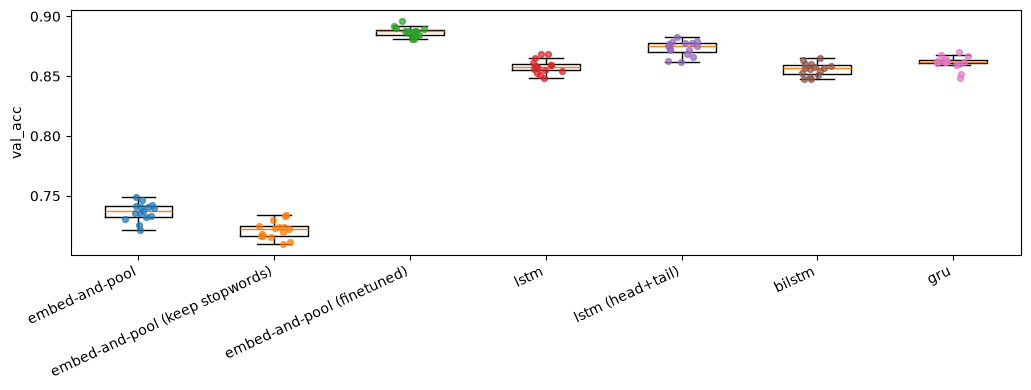

,mean,std,min,max,count
system,,,,,
bilstm,0.8559,0.0055,0.8472,0.8653,15
embed-and-pool,0.7368,0.0074,0.7217,0.7492,15
embed-and-pool (finetuned),0.8871,0.0039,0.8809,0.8960,15
embed-and-pool (keep stopwords),0.7215,0.0072,0.7099,0.7337,15
gru,0.8616,0.0055,0.8488,0.8705,15
lstm,0.8582,0.0058,0.8482,0.8687,15
lstm (head+tail),0.8733,0.0063,0.8617,0.8832,15


In [79]:
cv_df = pd.DataFrame(cv_rows)

def plot_box_and_points(df, value='val_acc'):
    systems = list(dict.fromkeys(df['system']))
    data = [df.loc[df['system'] == s, value].to_numpy() for s in systems]
    fig, ax = plt.subplots(figsize=(max(6, 1.5 * len(systems)), 4))
    ax.boxplot(data, showfliers=False)
    jitter = np.random.RandomState(0)
    for i, d in enumerate(data, 1):
        ax.scatter(i + jitter.uniform(-0.12, 0.12, len(d)), d, s=18, alpha=0.7, zorder=3)
    ax.set_xticks(range(1, len(systems) + 1))
    ax.set_xticklabels(systems, rotation=25, ha='right')
    ax.set_ylabel(value)
    plt.tight_layout()
    plt.show()

plot_box_and_points(cv_df)
cv_df.groupby('system')['val_acc'].agg(['mean', 'std', 'min', 'max', 'count']).round(4)

## 7. Data-size study

Does the recurrent encoder (and pretraining) need more data? Train on increasing subsets of fold 0's training portion and evaluate on its validation portion (one seed, to keep it cheap).

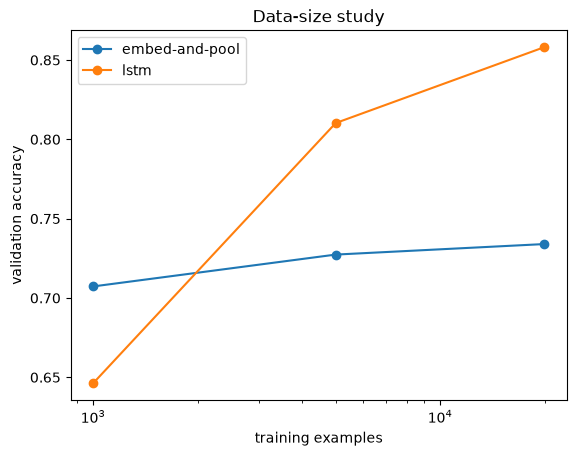

CPU times: user 4min 23s, sys: 4.49 s, total: 4min 27s
Wall time: 2min 51s


,n_train,system,val_acc
0,1000,embed-and-pool,0.707288
1,1000,lstm,0.646256
2,5000,embed-and-pool,0.727364
3,5000,lstm,0.810279
4,19923,embed-and-pool,0.733989
5,19923,lstm,0.858061


In [80]:
%%time
sizes = [500, 1000, 2000] if FAST_DEV else [1000, 5000, 25000]
sub_rs = np.random.RandomState(0)
fold0_train = [fold0['training'][i] for i in sub_rs.permutation(len(fold0['training']))]
size_rows = []
for n in sizes:
    n = min(n, len(fold0_train))
    for name, tok, cfg, opt in [('embed-and-pool', tok_bow, cfg_pool, {}), ('lstm', tok_rnn, cfg_lstm, {'batch_size': 32})]:
        m, best = train(fold0_train[:n], fold0['validation'], tok, cfg, opt, DEVICE,
                        results_folder / f"size-{n}-{name}", verbose=False)
        size_rows.append({'n_train': n, 'system': name, 'val_acc': m[best]['val_acc']})
size_df = pd.DataFrame(size_rows)
for name, g in size_df.groupby('system'):
    plt.plot(g['n_train'], g['val_acc'], marker='o', label=name)
plt.xscale('log'); plt.xlabel('training examples'); plt.ylabel('validation accuracy'); plt.legend()
plt.title("Data-size study"); plt.show()
size_df

## 8. Error analysis

### 8.1 Features of each devtest review

Computed from the untruncated tokens, so every system sees the same feature values.

In [81]:
import textstat

NEGATION_TOKENS = {"not", "no", "never", "n't", "nt", "nothing", "nobody", "none", "neither", "nor", "cannot", "nowhere"}
CONTRAST_TOKENS = {"but", "however", "although", "though", "yet", "despite", "nevertheless", "whereas"}

def featurize(text):
    toks = base_tokens(text)
    n = max(len(toks), 1)
    n_pos = sum(t in pos_lex for t in toks)
    n_neg = sum(t in neg_lex for t in toks)
    return {
        'length': len(toks),
        'oov_rate': sum(t not in glove for t in toks) / n,
        'negations': sum(t in NEGATION_TOKENS for t in toks),
        'lex_pos': n_pos,
        'lex_neg': n_neg,
        'lex_mixed': min(n_pos, n_neg),          # mixed reviews should be hard
        'lex_balance': (n_pos - n_neg) / n,      # net polarity density
        'contrast': sum(t in CONTRAST_TOKENS for t in toks),
        'exclaim': sum(t == '!' for t in toks),
        'question': sum(t == '?' for t in toks),
        'flesch_reading_ease': textstat.flesch_reading_ease(clean_text(text)),
    }

feature_cols = ['length', 'oov_rate', 'negations', 'lex_pos', 'lex_neg', 'lex_mixed', 'lex_balance',
                'contrast', 'exclaim', 'question', 'flesch_reading_ease']
devtest_feats = [pd.DataFrame([featurize(t) for t, _ in ts['devtest']]) for ts in my_test_sets]
devtest_feats[0].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
length,1000.0,260.924,200.113,36.000,143.750,196.000,314.000,2601.000
oov_rate,1000.0,0.009,0.010,0.000,0.000,0.006,0.013,0.068
negations,1000.0,3.520,3.194,0.000,1.000,3.000,5.000,22.000
lex_pos,1000.0,9.745,7.601,0.000,5.000,8.000,13.000,62.000
lex_neg,1000.0,8.968,8.046,0.000,4.000,7.000,12.000,82.000
lex_mixed,1000.0,6.518,5.720,0.000,3.000,5.000,8.000,55.000
lex_balance,1000.0,0.005,0.033,-0.116,-0.017,0.003,0.025,0.138
contrast,1000.0,2.209,2.180,0.000,1.000,2.000,3.000,17.000
exclaim,1000.0,0.878,1.927,0.000,0.000,0.000,1.000,20.000
question,1000.0,0.637,1.523,0.000,0.000,0.000,1.000,21.000


### 8.2 Predictions of every trained fold on the devtest set

In [82]:
%%time
rows, systems, items = [], {}, {}
for name in system_cfg:
    sid = systems.setdefault(name, len(systems))
    for run, seed in enumerate(SEEDS):
        dev = my_test_sets[run]['devtest']
        texts = [t for t, _ in dev]
        labels = np.array([l for _, l in dev], dtype=int)
        feats = devtest_feats[run]
        for fold in range(NUM_FOLDS):
            model = load_model(f"{results_folder}/{name}/seed-{seed}/fold-{fold}")
            logprobs = predict_logprobs(model, system_tokenizer[name], texts, 64, DEVICE)
            preds = logprobs.argmax(-1)
            conf = np.exp(logprobs.max(-1))
            for i in range(len(preds)):
                item_id = items.setdefault((run, my_test_sets[run]['devtest_ids'][i]), len(items))
                rows.append({'system': name, 'system_id': sid, 'item_id': item_id, 'run': run, 'fold': fold,
                             'label': labels[i], 'pred': preds[i], 'correct': int(labels[i] == preds[i]),
                             'confidence': conf[i], **feats.iloc[i].to_dict()})
df = pd.DataFrame(rows)
print(df.shape)
print(df.groupby('system')['correct'].mean().round(4))

(105000, 20)
system
bilstm                             0.8561
embed-and-pool                     0.7267
embed-and-pool (finetuned)         0.8834
embed-and-pool (keep stopwords)    0.7133
gru                                0.8659
lstm                               0.8615
lstm (head+tail)                   0.8749
Name: correct, dtype: float64
CPU times: user 21.9 s, sys: 764 ms, total: 22.7 s
Wall time: 15.9 s


In [83]:
for name in system_cfg:
    sub = df[(df['system'] == name) & (df['run'] == 0) & (df['fold'] == 0)]
    print(name)
    print(classification_report(sub['label'], sub['pred'], target_names=CLASS_NAMES, digits=3))

embed-and-pool
              precision    recall  f1-score   support

    negative      0.714     0.773     0.742       497
    positive      0.755     0.694     0.723       503

    accuracy                          0.733      1000
   macro avg      0.735     0.733     0.733      1000
weighted avg      0.735     0.733     0.733      1000

embed-and-pool (keep stopwords)
              precision    recall  f1-score   support

    negative      0.706     0.728     0.717       497
    positive      0.723     0.700     0.711       503

    accuracy                          0.714      1000
   macro avg      0.714     0.714     0.714      1000
weighted avg      0.714     0.714     0.714      1000

embed-and-pool (finetuned)
              precision    recall  f1-score   support

    negative      0.889     0.905     0.897       497
    positive      0.905     0.889     0.897       503

    accuracy                          0.897      1000
   macro avg      0.897     0.897     0.897      1000


### 8.3 Bayesian model of correctness

Observables: correctness $c_n$, system id $s_n$, feature vector $\mathbf f_n$. Latents (all Laplace(0, 1) priors, which encourage zero weights): global logit $\phi$, system shifts $\delta_s$, per-system feature weights $\mathbf w_s$.

$$c_n \sim \operatorname{Bernoulli}(\operatorname{sigmoid}(\phi + \delta_{s_n} + \mathbf w_{s_n}^\top \mathbf f_n))$$

Features are standardised before fitting, so weights are comparable. We also record each system's accuracy as a derived quantity. Inference uses NUTS (MCMC) from numpyro.

In [84]:
import jax
import jax.numpy as jnp
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS


def one_hot(a, k):
    return np.eye(k)[np.asarray(a, dtype=int)]


def bda_model(sys_id, features, num_systems, correctness=None):
    n, f = features.shape
    phi = numpyro.sample('phi', dist.Laplace(0., 1.))
    sys_shift = numpyro.sample('sys_shift', dist.Laplace(jnp.zeros(num_systems), 1.).to_event(1))
    w = numpyro.sample('w', dist.Laplace(jnp.zeros((num_systems, f)), 1.).to_event(2))
    mu = phi + sys_shift[sys_id] + jnp.sum(w[sys_id] * features, axis=-1)
    with numpyro.plate('obs_plate', n):
        numpyro.sample('obs', dist.Bernoulli(logits=mu), obs=correctness)
    membership = jax.nn.one_hot(sys_id, num_systems)
    numpyro.deterministic('accuracy', (membership * jax.nn.sigmoid(mu)[:, None]).sum(0) / membership.sum(0))


def fit_bda_model(num_systems, sys_id, features, correctness, num_chains=2, num_warmup=500, num_samples=500, seed=0):
    features = np.asarray(features, dtype=np.float32)
    std = features.std(0)
    features = (features - features.mean(0)) / np.where(std > 0, std, 1.0)      # standardise
    mcmc = MCMC(NUTS(bda_model), num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains, progress_bar=True)
    mcmc.run(jax.random.PRNGKey(seed), sys_id=jnp.asarray(sys_id, dtype=jnp.int32), features=jnp.asarray(features),
             num_systems=num_systems, correctness=jnp.asarray(correctness, dtype=jnp.int32))
    return mcmc

In [85]:
%%time
df_model = df.copy()
df_model['length'] = np.log1p(df_model['length'])      # tame the heavy right tail of review length

mcmc = fit_bda_model(
    num_systems=len(systems),
    sys_id=df_model['system_id'].to_numpy(),
    features=np.hstack([
        one_hot(df_model['pred'].to_numpy(), NUM_CLASSES),          # which class the system predicted
        df_model[feature_cols].to_numpy(dtype=float),
    ]),
    correctness=df_model['correct'].to_numpy(),
    num_chains=2,
)
mcmc.print_summary(exclude_deterministic=True)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]


                  mean       std    median      5.0%     95.0%     n_eff     r_hat
         phi      1.63      0.41      1.69      0.92      2.18    137.04      1.02
sys_shift[0]     -0.59      0.41     -0.66     -1.18      0.09    137.73      1.02
sys_shift[1]     -0.67      0.41     -0.74     -1.26     -0.02    137.04      1.02
sys_shift[2]      0.47      0.41      0.40     -0.08      1.17    138.00      1.02
sys_shift[3]      0.29      0.40      0.22     -0.27      0.98    136.68      1.02
sys_shift[4]      0.38      0.41      0.30     -0.17      1.06    138.07      1.02
sys_shift[5]      0.24      0.41      0.17     -0.34      0.92    135.84      1.02
sys_shift[6]      0.33      0.41      0.25     -0.27      0.99    137.30      1.02
      w[0,0]     -0.08      0.73     -0.09     -1.28      1.10    582.66      1.00
      w[0,1]      0.07      0.73      0.06     -1.10      1.27    581.00      1.00
      w[0,2]     -0.23      0.04     -0.23     -0.29     -0.17   1095.28      1.00
   

Convergence check: `r_hat` should be ~1.0 and there should be (almost) no divergences.

In [86]:
samples = mcmc.get_samples()
print("Weight samples:", samples['w'].shape)
print("Divergences:", int(mcmc.get_extra_fields()['diverging'].sum()))

Weight samples: (1000, 7, 13)
Divergences: 0


In [87]:
import arviz as az

system_names = [n for n, _ in sorted(systems.items(), key=lambda p: p[1])]
feature_names = [f"pred:{n}" for n in CLASS_NAMES] + feature_cols

posterior_data = az.from_numpyro(
    mcmc,
    coords={'system': system_names, 'feature': feature_names},
    dims={'sys_shift': ['system'], 'w': ['system', 'feature'], 'accuracy': ['system']},
    log_likelihood=False,
)
az_stats_params = {'point_estimate': 'median', 'ci_kind': 'hdi', 'ci_probs': (0.5, 0.95)}

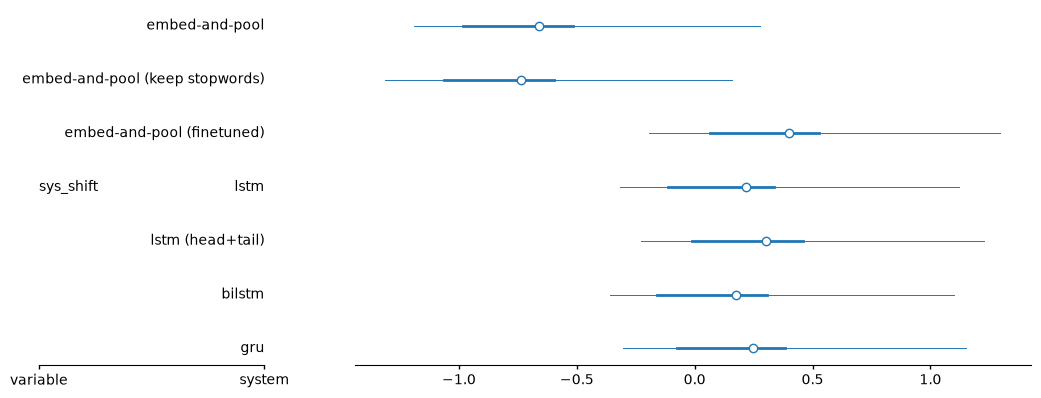

In [88]:
az.plot_forest(posterior_data, var_names=['sys_shift'], combined=True, **az_stats_params)

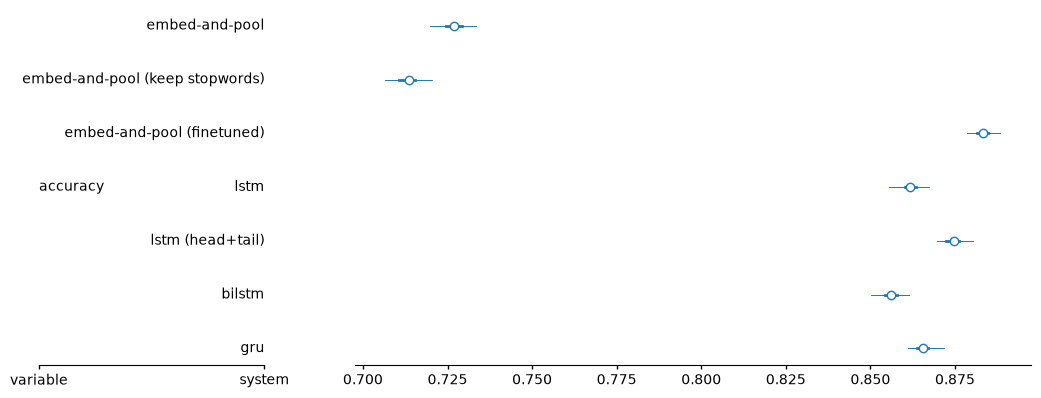

In [89]:
az.plot_forest(posterior_data, var_names=['accuracy'], combined=True, **az_stats_params)

Feature weights per system (standardised features). Below 0: the system does worse as the feature grows; above 0: better; near 0: the feature does not explain that system's correctness.

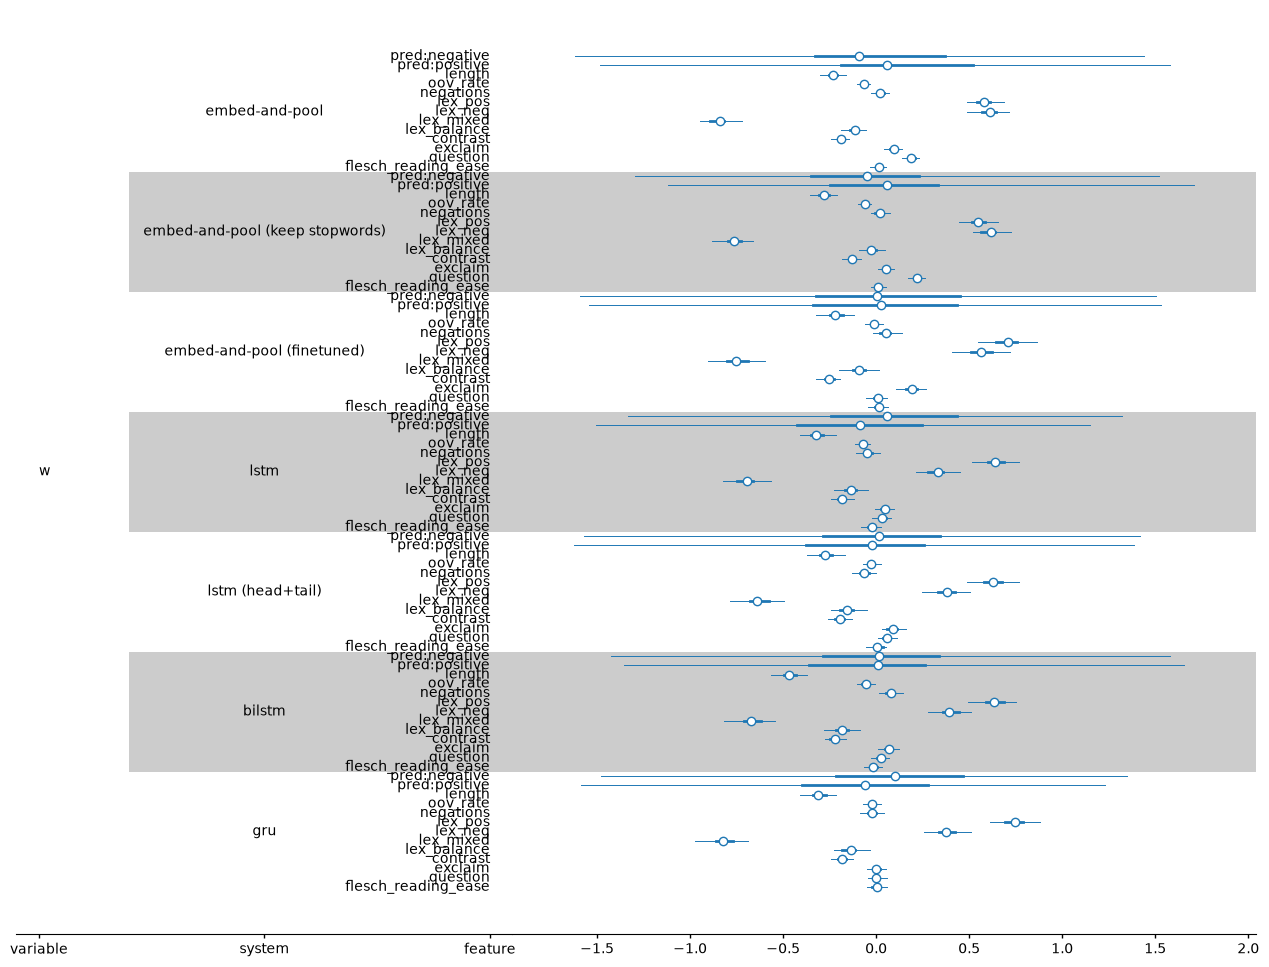

In [90]:
az.plot_forest(
    posterior_data, var_names=['w'], combined=True, shade_label="system",
    figure_kwargs={"figsize": (16, 12), "width_ratios": [2, 3], "layout": "none"},
    **az_stats_params,
)

Same weights grouped by feature, so systems sit side by side:

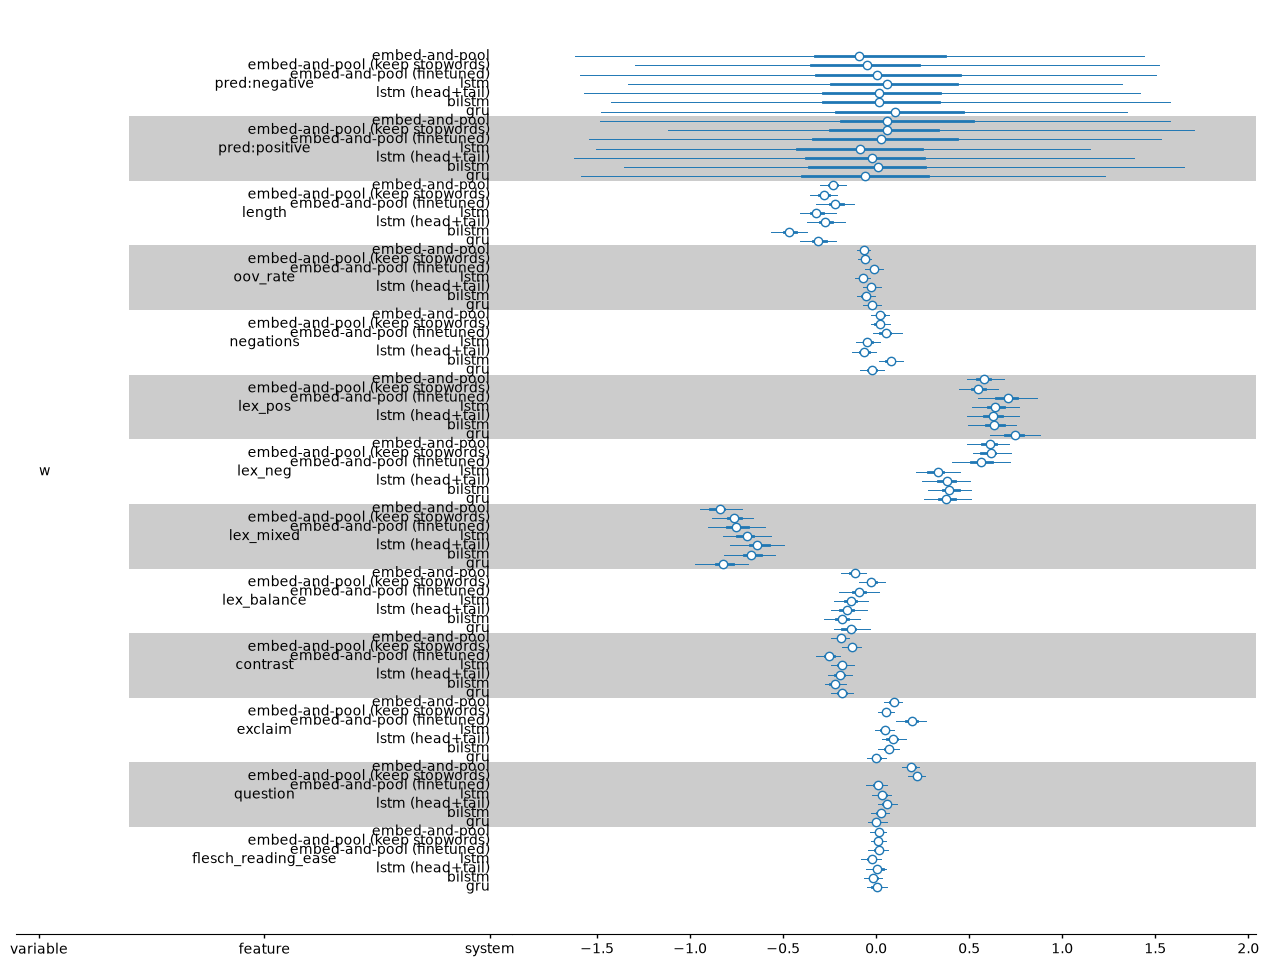

In [91]:
plot_data = posterior_data.copy()
plot_data["posterior"] = posterior_data.posterior["w"].transpose("chain", "draw", "feature", "system").to_dataset()
az.plot_forest(
    plot_data, var_names=["w"], combined=True, shade_label="feature",
    figure_kwargs={"figsize": (16, 12), "width_ratios": [2, 3], "layout": "none"},
    **az_stats_params,
)

### 8.4 Read actual errors

The statistics tell you where to look; the examples tell you why.

In [92]:
fold_df = df[(df['run'] == 0) & (df['fold'] == 0)]
wide = fold_df.pivot(index='item_id', columns='system', values='correct')
item_text = {items[(0, i)]: t for i, (t, _) in zip(my_test_sets[0]['devtest_ids'], my_test_sets[0]['devtest'])}

if {'embed-and-pool', 'lstm'} <= set(wide.columns):
    lstm_only = wide[(wide['lstm'] == 1) & (wide['embed-and-pool'] == 0)].index[:3]
    pool_only = wide[(wide['lstm'] == 0) & (wide['embed-and-pool'] == 1)].index[:3]
    print("=== LSTM right, embed-and-pool wrong ===")
    for it in lstm_only:
        print(clean_text(item_text[it])[:500], "\n---")
    print("=== embed-and-pool right, LSTM wrong ===")
    for it in pool_only:
        print(clean_text(item_text[it])[:500], "\n---")

=== LSTM right, embed-and-pool wrong ===
Bobby and Mikey are two little boys who move across the country with their divorced mother to start a new life. Soon after the family settles in, their mom marries "The King" who ends up being an abusive stepfather, especially to Bobby. So Bobby decides that he will "fly away" from the abuse in his birthday present. This movie was difficult to watch, especially the abuse scenes. It was hard to watch an innocent, playful little boy become abused and turn into a sullen scared, and withdrawn young  
---
(VERY mildly spoilerish) I must start by saying that I'm not usually impressed by science-fiction, so Pitch Black (2000) was a pleasant surprise. It had me hooked from the very beginning with rhythm, intensity and visual outburst that left me fascinated and glued to my seat. I'm very happy to say that this movie was the best (okay, at least *one* of the best) science fiction piece that I've seen in a long, long time. The plot in short might sound si